# HW04：降维、PCA 与 UMAP

姓名：郑瑶　学号：24520222202960

> 先运行数据检查，再按工作单完成四项任务。保留代码、实际输出和图；分析结论请根据自己的运行结果填写。

## 0. 数据检查

初始判断：不同意该同事说法；我目前认为，仅凭二维图分得开，还不足以证明疾病机制或预测新患者；信心（0–100）：60；需要的证据：需要知道这种方法在没有参与分析的新样本上是否仍然有效。


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

relative_data = Path("assignments/hw04/resources/data/leukemia/leukemia.csv")
repo_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / relative_data).is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError(
        "找不到课程数据。请在本 notebook 中运行，或确认打开的是 git-practice-classroom 仓库。"
    )

df = pd.read_csv(repo_root / relative_data)
metadata_columns = ["sample_id", "original_split", "diagnosis"]
X = df.drop(columns=metadata_columns)
y = df["diagnosis"]

print("Python：", sys.version.split()[0])
print("pandas：", pd.__version__)
print("NumPy：", np.__version__)
print("数据文件：", repo_root / relative_data)
print("表达矩阵形状：", X.shape)
print("类别数量：\n", y.value_counts().to_string())
print("是否全部为有限数值：", np.isfinite(X.to_numpy()).all())

assert X.shape == (72, 7129), f"数据形状异常：{X.shape}"
assert np.isfinite(X.to_numpy()).all(), "表达矩阵含非有限值"
assert set(y.unique()) == {"ALL", "AML"}, "诊断标签与预期不符"

Python： 3.12.10
pandas： 2.3.3
NumPy： 2.3.5
数据文件： d:\桌面\zy-workplace3\git-practice-classroom\assignments\hw04\resources\data\leukemia\leukemia.csv
表达矩阵形状： (72, 7129)
类别数量：
 diagnosis
ALL    47
AML    25
是否全部为有限数值： True


### 数据检查记录

- 一行代表：一份白血病样本的微阵列表达谱。
- 分析输入有 72 行、7,129 列。
- ALL 有 47 份，AML 有 25 份。
- 输入排除了 sample_id、original_split、diagnosis 三个元数据列。
- 每个输入列是一个探针特征，探针数不等于不同基因数。
- 数据检查显示，输入全部为有限数值。

## 1. 降维是为了看图，还是预测新样本？

为以下目标分别填写“需要什么输出”和“如何判断有用”：可视化；去噪；压缩特征；发现样本结构；作为后续模型输入。

| 目标 | 需要什么输出 | 如何判断有用 |
|---|---|---|
| 可视化 | 每个样本的二维或三维坐标图 | 能否帮助观察样本关系；改变参数后，主要观察是否稳定 |
| 去噪 | 减少不稳定变化后的数据表示 | 重复测量是否更稳定，或后续分析是否改善；不能只看图是否整齐 |
| 压缩特征 | 用较少的数表示每个样本 | 减少了多少特征、损失了多少信息、是否满足使用需求 |
| 发现样本结构 | 候选分组、连续变化或邻近关系 | 是否在不同设置下较稳定，是否得到其他信息和独立数据支持 |
| 作为后续模型输入 | 供预测方法使用的较少特征 | 在没有参与建立规则的样本上，预测是否可靠 |

画出两条流程：

1. 描述这 72 个样本：表达矩阵 → 标准化 → PCA/UMAP → 诊断着色。

```text
流程一：描述现在这 72 份样本

全部 72 份样本的 7,129 个探针测量值
                 ↓
在全部 72 份样本上拟合标准化，并转换数据
                 ↓
在标准化后的全部 72 份样本上拟合 PCA / UMAP
得到每份样本的低维坐标
                 ↓
拟合完成后，根据疾病类别给点着色
                 ↓
描述这批样本的结构
```

诊断标签不参与标准化及 PCA/UMAP 的拟合，只用于拟合后的着色。
这个流程用于描述已有样本，不能据此估计对新患者的预测表现。

2. 评估新样本预测：先划分数据 → 在训练折内拟合标准化、PCA 与分类器 → 转换并预测验证折 → 固定方案后评估测试集。

```text
流程二：评估对新样本的预测能力

先划分开发数据与最终测试数据
                 ↓
在开发数据内进行交叉验证：
每次取其中一部分作为训练折，另一部分作为验证折
                 ↓
仅在当次训练折内：
拟合标准化 → 拟合 PCA → 训练分类器
                 ↓
对当次验证折：
使用训练折已经确定的标准化和 PCA 进行转换
→ 用训练好的分类器预测
→ 比较预测类别与真实类别
                 ↓
更换训练折和验证折，重复以上过程
每次都重新在当次训练折内拟合全部步骤
                 ↓
汇总各折表现，确定并固定分析方案
                 ↓
按固定方案，在全部开发数据上重新拟合完整流程
                 ↓
对未参与方案选择的最终测试数据进行转换、预测和评价
```

为什么“PCA 没用标签，所以可以在全数据上先做 PCA 再交叉验证”仍会泄露信息。

答：PCA 不使用诊断标签，但仍然需要根据输入数据确定主成分方向；标准化也需要根据数据计算各个特征的均值和标准差。因此，即使没有使用验证样本的疾病标签，提前使用它们的测量值来确定这些规则，仍然会造成信息泄露。如果先在全部样本上拟合，再进行交叉验证，验证样本就已经影响了处理规则。因此，评价预测能力时，标准化、PCA 和分类器都应该只在每个训练部分中拟合，再用于处理和预测验证部分。

本次未运行可选交叉验证；后续 PCA/UMAP 均为全部 72 份样本的描述性分析，不能作为新患者预测表现的证据。


## 2. PCA 对照

完成标准化 PCA、原尺度 PCA、解释率图、PC1–PC2 图和 PC1 前五个带符号权重。

### 2.1 按探针标准化

本任务描述全部 72 份样本，输入为全部 7,129 个探针。
不使用诊断标签拟合标准化。

方法：对每个探针分别减去该列均值，再除以该列总体标准差。
使用 StandardScaler，标准差计算方式为 ddof=0。

运行前预测：
标准化后，每列均值应接近 0，总体标准差应接近 1，
矩阵形状仍为 (72, 7129)。

In [2]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.preprocessing import StandardScaler

# 使用原始探针测量表，不包含三个元数据列
assert X.shape == (72, 7129)

# 检查是否有完全不变化的列；本课程数据预期没有
constant_count = (X.std(axis=0, ddof=0) == 0).sum()
print("常量探针数量：", constant_count)
assert constant_count == 0

# 描述性分析：在全部 72 份样本上，按列拟合和转换
scaler = StandardScaler()
Z = scaler.fit_transform(X)

# 检查每列的均值和总体标准差
column_means = Z.mean(axis=0)
column_stds = Z.std(axis=0, ddof=0)

mean_error = np.abs(column_means).max()
std_error = np.abs(column_stds - 1).max()

print("scikit-learn：", sklearn.__version__)
print("标准化前形状：", X.shape)
print("标准化后形状：", Z.shape)
print("所有列中，均值偏离 0 的最大程度：", mean_error)
print("所有列中，标准差偏离 1 的最大程度：", std_error)
print("标准化后是否全部为有限数值：", np.isfinite(Z).all())

# 允许计算机浮点运算产生的极小误差
assert np.allclose(column_means, 0, atol=1e-10)
assert np.allclose(column_stds, 1, atol=1e-10)

# 展示前 5 份样本、前 3 个探针的标准化值
preview = pd.DataFrame(
    Z[:5, :3],
    index=df["sample_id"].iloc[:5].to_numpy(),
    columns=X.columns[:3]
)
print("\n标准化结果局部预览：")
print(preview.to_string())

常量探针数量： 0
scikit-learn： 1.8.0
标准化前形状： (72, 7129)
标准化后形状： (72, 7129)
所有列中，均值偏离 0 的最大程度： 5.982868521591122e-16
所有列中，标准差偏离 1 的最大程度： 3.3306690738754696e-16
标准化后是否全部为有限数值： True

标准化结果局部预览：
      AFFX-BioB-5_at  AFFX-BioB-M_at  AFFX-BioB-3_at
G001       -1.024310        0.074633       -0.409794
G002       -0.251570        0.912622        0.058021
G003        0.397532        1.164019       -2.453409
G004       -0.210357        0.483153        2.241159
G005        0.088436        0.367929       -0.557526


### 标准化结果与解释

标准化后的矩阵形状为 `(72, 7129)`；各列均值偏离 0 的最大程度约为 `5.98 × 10⁻¹⁶`，总体标准差偏离 1 的最大程度约为 `3.33 × 10⁻¹⁶`。这说明按探针完成了标准化，极小偏差来自浮点运算精度。

解释标准化与微阵列上游归一化不是同一步骤：这里的 `StandardScaler` 只是对已经得到的表达矩阵按列重新计算中心和尺度，使每个探针在本次分析中均值接近 0、总体标准差接近 1；它不负责修正实验流程中的芯片、测量或其他系统性差异，也不能替代上游归一化或批次处理。由于本数据含有负值，本任务不对原始矩阵直接使用 `log` 或 `log1p` 变换。

常量探针数量为 0，标准化后的数据全部为有限数值；标准化改变尺度，不减少特征数量。


### 2.2 标准化 PCA：解释率与二维展示

分析输入为标准化矩阵 Z，包含全部 72 份样本、7,129 个探针。
PCA 在全部 72 份样本上拟合，仅用于描述当前数据。
诊断标签不参与 PCA 拟合，只用于事后着色。

运行前预测：
我认为前两个主成分会保留一部分数据变化，但不一定足以代表全部数据。
它们也不一定能将 ALL 与 AML 完全分开。

In [3]:
from sklearn.decomposition import PCA

# 对前一步得到的标准化矩阵拟合 PCA
pca = PCA(svd_solver="full")
pca.fit(Z)

# 计算每份样本在各主成分上的坐标，即样本得分
scores = pca.transform(Z)

# 每个主成分的方差解释率
evr = pca.explained_variance_ratio_

# 从 PC1 开始，逐项相加，得到累计解释率
cumulative_evr = np.cumsum(evr)

print(f"PC1 方差解释率：{evr[0]:.4%}")
print(f"PC2 方差解释率：{evr[1]:.4%}")
print(f"前两轴累计解释率：{evr[:2].sum():.4%}")

# 展示前 5 份样本的前两个新坐标
score_preview = pd.DataFrame({
    "sample_id": df["sample_id"].iloc[:5].to_numpy(),
    "PC1": scores[:5, 0],
    "PC2": scores[:5, 1],
})

print("\n前 5 份样本的 PCA 坐标：")
print(score_preview.to_string(index=False))

PC1 方差解释率：14.9216%
PC2 方差解释率：9.4462%
前两轴累计解释率：24.3678%

前 5 份样本的 PCA 坐标：
sample_id        PC1       PC2
     G001  27.105207  6.448490
     G002   3.507419 15.845801
     G003  60.006379 10.392307
     G004  20.640386 -2.623372
     G005 -21.012018 41.794160


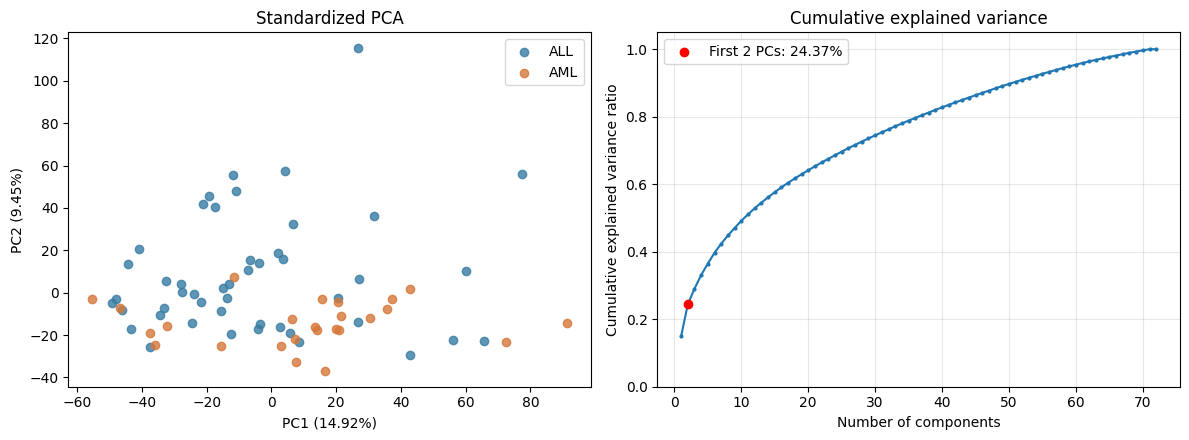

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 左图：PC1-PC2 散点图
# PCA 已经拟合完成，此处诊断标签仅用于着色
for label, color in [("ALL", "#387ca3"), ("AML", "#d57839")]:
    mask = df["diagnosis"].eq(label).to_numpy()

    axes[0].scatter(
        scores[mask, 0],
        scores[mask, 1],
        label=label,
        color=color,
        alpha=0.8
    )

axes[0].set(
    xlabel=f"PC1 ({evr[0]:.2%})",
    ylabel=f"PC2 ({evr[1]:.2%})",
    title="Standardized PCA"
)
axes[0].legend()

# 右图：累计方差解释率
component_numbers = np.arange(1, len(evr) + 1)

axes[1].plot(
    component_numbers,
    cumulative_evr,
    marker=".",
    markersize=4
)

# 标记前两个主成分的累计解释率
axes[1].scatter(
    [2],
    [cumulative_evr[1]],
    color="red",
    zorder=3,
    label=f"First 2 PCs: {cumulative_evr[1]:.2%}"
)

axes[1].set(
    xlabel="Number of components",
    ylabel="Cumulative explained variance ratio",
    title="Cumulative explained variance",
    ylim=(0, 1.05)
)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 标准化 PCA 的实际结果与解释

标准化 PCA 的结果为：PC1 解释率 `14.9216%`，PC2 解释率 `9.4462%`，前两轴累计解释率 `24.3678%`。

在 PC1–PC2 散点图中，每个点代表一份样本，坐标由探针测量值计算得到，诊断标签仅用于事后着色。较高 PC2 得分的区域主要为 ALL 样本，AML 样本多数位于PC2 较低的区域，但较低区域也有不少 ALL 样本，这说明PC1–PC2 图中两类样本有一定分布差异，尤其在 PC2 方向上有所体现，但仍有明显重叠；前两轴只显示当前输入总方差的一部分。

累计解释率曲线随主成分数量增加而上升，且逐渐变缓，
表明前面的主成分各自保留更多方差。
前两个主成分只保留约 24.37% 的输入总方差，
其余约 75.63% 位于未显示的其他主成分方向中。
因此，二维图不能代表全部数据变化。


### 2.3 PC1 的方向权重

本课将 pca.components_.T 定义为主成分方向权重矩阵（loading）。
本步骤提取 PC1 中绝对权重最大的 5 个探针，同时保留权重正负号。

运行前判断：
PC1 是多个探针的加权组合，前五个探针只是用于帮助解释这个方向。
绝对权重大，不代表它就是致病基因，也不等于分类重要性。

In [5]:
# 每行对应一个探针，每列对应一个主成分
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=[
        f"PC{i + 1}"
        for i in range(pca.components_.shape[0])
    ]
)

# 取出全部 7,129 个探针的 PC1 权重
pc1_weights = loadings["PC1"]

# 按绝对值从大到小选出 5 个，但保留原来的正负号
top5_names = pc1_weights.abs().nlargest(5).index

pc1_top5 = pd.DataFrame({
    "探针": top5_names,
    "PC1方向权重": pc1_weights.loc[top5_names].to_numpy(),
    "权重绝对值": pc1_weights.loc[top5_names].abs().to_numpy()
})

print("PC1 绝对权重最大的 5 个探针：")
print(
    pc1_top5.to_string(
        index=False,
        float_format=lambda value: f"{value:+.6f}"
    )
)

PC1 绝对权重最大的 5 个探针：
         探针   PC1方向权重     权重绝对值
X92518_s_at +0.028786 +0.028786
  X95190_at -0.028177 +0.028177
  X98253_at +0.027927 +0.027927
  X82895_at +0.027871 +0.027871
  Y09616_at +0.027757 +0.027757


In [6]:
# 以第一份样本为例，使用全部探针计算 PC1 得分
sample_position = 0
sample_id = df["sample_id"].iloc[sample_position]

# PCA transform 会减去拟合时的输入均值
# Z 已经按列标准化，因此这里的 pca.mean_ 应非常接近 0
centered_sample = Z[sample_position] - pca.mean_

# 每个探针的值乘以对应权重，再将全部加权项相加
weighted_terms = centered_sample * pc1_weights.to_numpy()
calculated_score = weighted_terms.sum()

print("样本编号：", sample_id)
print(f"全部探针加权求和得到的 PC1：{calculated_score:.6f}")
print(f"pca.transform 得到的 PC1：{scores[sample_position, 0]:.6f}")

样本编号： G001
全部探针加权求和得到的 PC1：27.105207
pca.transform 得到的 PC1：27.105207


### PC1 权重结果与解释

本课将 `pca.components_.T` 定义为主成分方向权重（loading）。PC1 绝对权重最大的 5 个探针为：

| 探针 | PC1 方向权重 |
|---|---:|
| `X92518_s_at` | `+0.028786` |
| `X95190_at` | `-0.028177` |
| `X98253_at` | `+0.027927` |
| `X82895_at` | `+0.027871` |
| `Y09616_at` | `+0.027757` |

PC1 是全部 7,129 个标准化探针的加权组合，不是单一探针；上述 5 个探针只是帮助解释方向，不是 PC1 的全部输入。正负号表示沿当前 PC1 方向的作用方向，整体翻转所有权重和样本得分只会改变坐标轴朝向，不改变解释率和样本间关系。

解释样本的 PC1 得分如何由标准化特征加权得到：先把样本在每个探针上的表达值减去该探针的均值，再除以该探针的总体标准差，得到标准化值。然后，把每个标准化值乘以该探针对应的 PC1 方向权重，最后将全部 7,129 项相加，就得到该样本在 PC1 轴上的坐标，也叫 PC1 得分。

具体计算方法如下：
设第 i 个样本在第 j 个探针上的原始值为 xᵢⱼ，该探针的均值和总体标准差分别为 μⱼ、σⱼ，PC1 权重为 wⱼ，则：

```text
标准化值：zᵢⱼ = (xᵢⱼ − μⱼ) / σⱼ
PC1 得分：tᵢ₁ = Σⱼ₌₁⁷¹²⁹ (zᵢⱼ − mⱼ) × wⱼ
```

其中 mⱼ 是 PCA 拟合时记录的输入列均值，即 `pca.mean_`；因为输入已经标准化，所以 mⱼ 非常接近 0，通常可以把这个计算理解为 `PC1 得分 ≈ 全部标准化值与对应权重乘积之和`。得分是所有探针共同贡献的结果，不能只用绝对权重最大的 5 个探针代替全部探针。以 G001 为例，全部探针加权求和得到 `27.105207`，与 notebook 中 `pca.transform` 的结果一致；得分的正负表示位于当前 PC1 轴的哪一侧，不代表疾病轻重。

一句对 PC1 的解释和一句不能据此推出的结论：
- 对 PC1 的解释：本次标准化 PCA 的 PC1 是全部 7,129 个标准化探针的加权组合，在方向权重平方和为 1 的约束下，使这 72 份样本投影后的方差最大，并解释了标准化输入总方差的 `14.9216%`。
- 不能据此推出的结论：不能因为某个探针在 PC1 中的绝对权重较大，就认定它是导致 ALL/AML 的致病基因，也不能仅凭 PC1 得分判断新患者的诊断。


### 2.4 原尺度 PCA 对照

原尺度 PCA 直接使用原始探针测量值。
PCA 会按列中心化，但不进行 StandardScaler 的除标准差操作。

运行前预测：
原始尺度中数值范围和方差较大的探针可能更强地影响 PC1，
因此原尺度 PCA 的高权重探针可能与标准化 PCA 不同。
两种 PCA 的解释率不能只比较数值大小，
因为它们对应的输入总方差不同。

In [7]:
# 原尺度 PCA：
# PCA 默认会中心化每一列，但不会进行标准化缩放
raw_pca = PCA(svd_solver="full")
raw_scores = raw_pca.fit_transform(X)

raw_evr = raw_pca.explained_variance_ratio_
raw_cumulative_evr = np.cumsum(raw_evr)

# 原尺度 PC1 的方向权重
raw_pc1_weights = pd.Series(
    raw_pca.components_[0],
    index=X.columns,
    name="原尺度_PC1方向权重"
)

raw_top5_names = raw_pc1_weights.abs().nlargest(5).index

raw_pc1_top5 = pd.DataFrame({
    "探针": raw_top5_names,
    "原尺度_PC1方向权重": raw_pc1_weights.loc[raw_top5_names].to_numpy(),
    "权重绝对值": raw_pc1_weights.loc[raw_top5_names].abs().to_numpy()
})

print("原尺度 PCA 的 PC1 方差解释率：", f"{raw_evr[0]:.4%}")
print("原尺度 PCA 的 PC2 方差解释率：", f"{raw_evr[1]:.4%}")
print("原尺度 PCA 前两轴累计解释率：", f"{raw_evr[:2].sum():.4%}")

print("\n原尺度 PCA 的 PC1 绝对权重最大的 5 个探针：")
print(
    raw_pc1_top5.to_string(
        index=False,
        float_format=lambda value: f"{value:+.6f}"
    )
)

# 汇总标准化 PCA 和原尺度 PCA 的解释率
evr_comparison = pd.DataFrame({
    "方法": ["标准化 PCA", "原尺度 PCA"],
    "PC1解释率": [evr[0], raw_evr[0]],
    "PC2解释率": [evr[1], raw_evr[1]],
    "前两轴累计解释率": [
        evr[:2].sum(),
        raw_evr[:2].sum()
    ]
})

print("\n两种 PCA 的解释率比较：")
print(
    evr_comparison.to_string(
        index=False,
        formatters={
            "PC1解释率": lambda value: f"{value:.4%}",
            "PC2解释率": lambda value: f"{value:.4%}",
            "前两轴累计解释率": lambda value: f"{value:.4%}"
        }
    )
)

原尺度 PCA 的 PC1 方差解释率： 17.4278%
原尺度 PCA 的 PC2 方差解释率： 10.3386%
原尺度 PCA 前两轴累计解释率： 27.7664%

原尺度 PCA 的 PC1 绝对权重最大的 5 个探针：
                探针  原尺度_PC1方向权重     权重绝对值
       M25079_s_at    +0.352388 +0.352388
        hum_alu_at    +0.313552 +0.313552
HG1428-HT1428_s_at    +0.234867 +0.234867
         L06499_at    +0.210453 +0.210453
       J04617_s_at    +0.196253 +0.196253

两种 PCA 的解释率比较：
     方法   PC1解释率   PC2解释率 前两轴累计解释率
标准化 PCA 14.9216%  9.4462% 24.3678%
原尺度 PCA 17.4278% 10.3386% 27.7664%


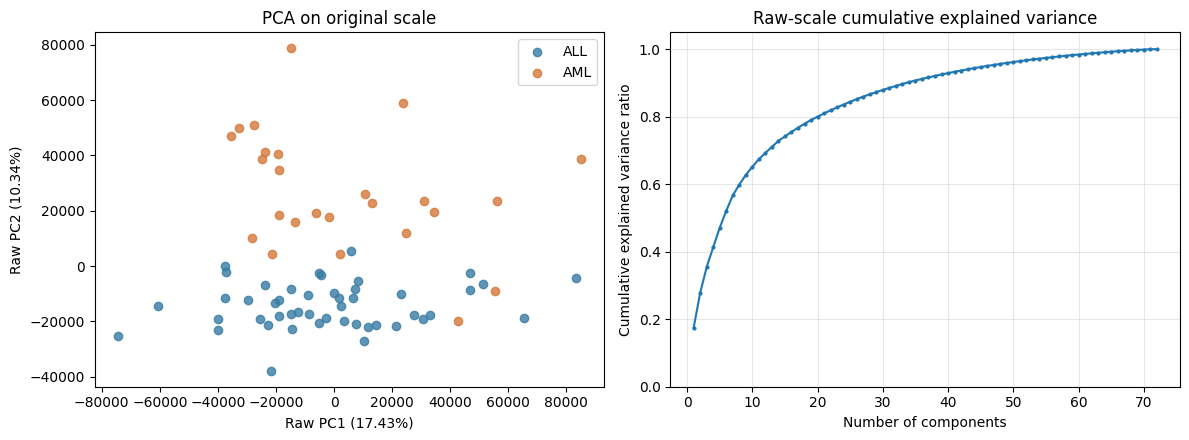

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 原尺度 PC1-PC2 散点图
for label, color in [("ALL", "#387ca3"), ("AML", "#d57839")]:
    mask = df["diagnosis"].eq(label).to_numpy()

    axes[0].scatter(
        raw_scores[mask, 0],
        raw_scores[mask, 1],
        label=label,
        color=color,
        alpha=0.8
    )

axes[0].set(
    xlabel=f"Raw PC1 ({raw_evr[0]:.2%})",
    ylabel=f"Raw PC2 ({raw_evr[1]:.2%})",
    title="PCA on original scale"
)
axes[0].legend()

# 原尺度累计解释率
axes[1].plot(
    np.arange(1, len(raw_evr) + 1),
    raw_cumulative_evr,
    marker=".",
    markersize=4
)

axes[1].set(
    xlabel="Number of components",
    ylabel="Cumulative explained variance ratio",
    title="Raw-scale cumulative explained variance",
    ylim=(0, 1.05)
)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 原尺度 PCA 的实际结果与解释

原尺度 PCA 只进行中心化，不进行除标准差缩放。其 PC1 解释率为 `17.4278%`，PC2 为 `10.3386%`，前两轴累计解释率为 `27.7664%`；标准化 PCA 的对应结果为 `14.9216%`、`9.4462%` 和 `24.3678%`。两者基于不同的输入总方差，不能只因为原尺度 PCA 解释率较高就判断其更好。

原尺度 PC1 绝对权重最大的 5 个探针为：

| 探针 | 原尺度 PC1 方向权重 |
|---|---:|
| `M25079_s_at` | `+0.352388` |
| `hum_alu_at` | `+0.313552` |
| `HG1428-HT1428_s_at` | `+0.234867` |
| `L06499_at` | `+0.210453` |
| `J04617_s_at` | `+0.196253` |

原尺度与标准化 PCA 的 PC1 前五个探针完全不同，说明主成分方向受到尺度处理影响。原尺度图中，两类样本在 PC2 方向上看起来有较明显的分布差异，但仍有重叠。原始范围或方差较大的探针可能更强地影响原尺度 PCA；标准化会减少这种尺度支配，但也可能放大低变异噪声。需要结合分析目的解释尺度选择，不能只凭解释率或图形分离判断哪种方法更好。

回答：PC1 最大化的是什么方差？它是否等于“最能区分 ALL/AML 的方向”或某一个基因？主成分符号整体翻转是否改变结果？中心化后的 72 个样本为什么至多有 71 个非零主成分？

答：PC1 最大化的是样本投影后的方差，并不等于最能区分 ALL/AML 的方向，也不等于某一个基因。较大的绝对权重不能单独证明差异表达显著、分类重要或具有致病作用。整体翻转主成分权重和样本得分的符号只会改变坐标轴朝向，不改变解释率和样本间关系。中心化后 72 个样本最多有 `72 - 1 = 71` 个独立变化方向，因此最多有 71 个非零主成分，尽管原始输入有 7,129 个探针。


## 3. UMAP 稳定性

完成基线及三个单因素对照，保存带样本编号的坐标，并解释稳定与变化的结构。

关于 UMAP 的理解：UMAP 先根据高维空间中的近邻关系构建局部结构，再把这些关系表示在二维图中。UMAP 主要用于探索局部邻域，不保证保留全部全局距离。UMAP1 和 UMAP2 没有固定的生物学含义，也没有 PCA 那样的方差解释率。图的旋转、翻转或整体位置变化不代表生物学变化。岛屿的数量、面积、方向和岛屿间距离也不能直接解释为真实亚型数量或疾病差异大小。

本任务继续使用任务二中的标准化矩阵 Z，包含全部 72 份样本和全部 7,129 个探针。诊断标签不参与 UMAP 拟合，只在拟合后用于给点着色。

运行前预测：
改变 n_neighbors、min_dist 或随机种子后，二维布局可能发生变化。
我会通过样本编号和邻近关系追踪哪些结构较稳定，而不是只选择看起来最分开的图。

### 3.1 运行基线和三个对照

In [9]:
import umap
from umap import UMAP

# 基线及三个单因素对照
umap_settings = {
    "baseline_n15_min01_seed42": {
        "n_neighbors": 15,
        "min_dist": 0.1,
        "random_state": 42
    },
    "neighbors5_min01_seed42": {
        "n_neighbors": 5,
        "min_dist": 0.1,
        "random_state": 42
    },
    "neighbors15_min05_seed42": {
        "n_neighbors": 15,
        "min_dist": 0.5,
        "random_state": 42
    },
    "neighbors15_min01_seed7": {
        "n_neighbors": 15,
        "min_dist": 0.1,
        "random_state": 7
    },
}

# 四次都使用同一个标准化矩阵 Z
# 诊断标签不传给 UMAP
embeddings = {}

for name, params in umap_settings.items():
    reducer = UMAP(
        n_components=2,
        metric="euclidean",
        n_jobs=1,
        **params
    )

    embeddings[name] = reducer.fit_transform(Z)
    print(f"完成：{name}")
    print(f"参数：{params}")

# 创建项目要求的结果目录
results_dir = (
    repo_root
    / ".tmp"
    / "dimension-reduction"
    / "student-results"
)
results_dir.mkdir(parents=True, exist_ok=True)

# 保存样本编号、诊断、PCA 坐标和四组 UMAP 坐标
umap_coordinates = df[["sample_id", "diagnosis"]].copy()

umap_coordinates["PCA1"] = scores[:, 0]
umap_coordinates["PCA2"] = scores[:, 1]

for name, embedding in embeddings.items():
    umap_coordinates[f"{name}_UMAP1"] = embedding[:, 0]
    umap_coordinates[f"{name}_UMAP2"] = embedding[:, 1]

coordinate_path = results_dir / "umap_coordinates.csv"
umap_coordinates.to_csv(coordinate_path, index=False)

print("\nUMAP 版本：", umap.__version__)
print("坐标表：", coordinate_path)
print("坐标表形状：", umap_coordinates.shape)
print(umap_coordinates.head().to_string(index=False))

完成：baseline_n15_min01_seed42
参数：{'n_neighbors': 15, 'min_dist': 0.1, 'random_state': 42}
完成：neighbors5_min01_seed42
参数：{'n_neighbors': 5, 'min_dist': 0.1, 'random_state': 42}
完成：neighbors15_min05_seed42
参数：{'n_neighbors': 15, 'min_dist': 0.5, 'random_state': 42}
完成：neighbors15_min01_seed7
参数：{'n_neighbors': 15, 'min_dist': 0.1, 'random_state': 7}

UMAP 版本： 0.5.12
坐标表： d:\桌面\zy-workplace3\git-practice-classroom\.tmp\dimension-reduction\student-results\umap_coordinates.csv
坐标表形状： (72, 12)
sample_id diagnosis       PCA1      PCA2  baseline_n15_min01_seed42_UMAP1  baseline_n15_min01_seed42_UMAP2  neighbors5_min01_seed42_UMAP1  neighbors5_min01_seed42_UMAP2  neighbors15_min05_seed42_UMAP1  neighbors15_min05_seed42_UMAP2  neighbors15_min01_seed7_UMAP1  neighbors15_min01_seed7_UMAP2
     G001       ALL  27.105207  6.448490                         7.527618                         1.749259                      10.055384                       1.022408                        4.242846             

### 3.2 画四组 UMAP 对照图

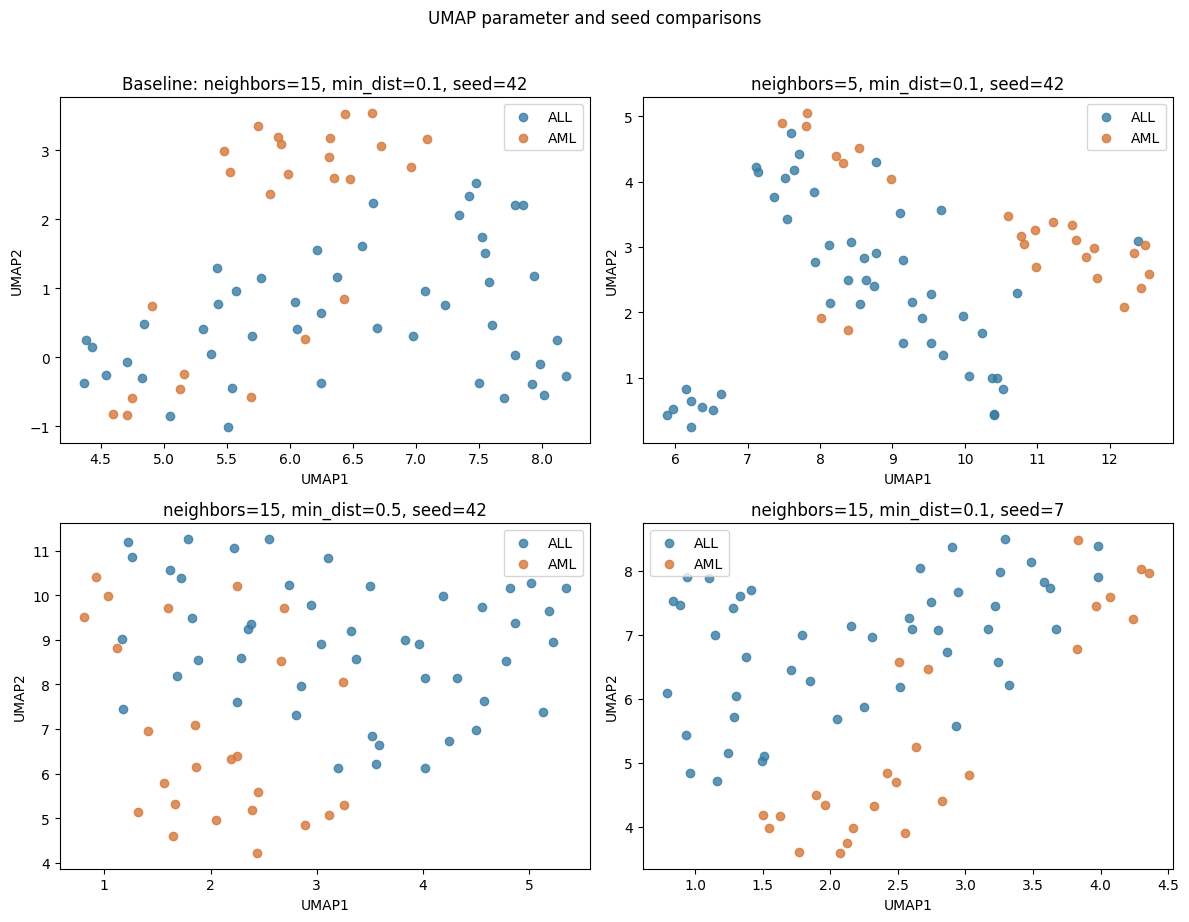

UMAP 参数对照图： d:\桌面\zy-workplace3\git-practice-classroom\.tmp\dimension-reduction\student-results\umap_parameter_comparison.png


In [10]:
import matplotlib.pyplot as plt

umap_titles = {
    "baseline_n15_min01_seed42":
        "Baseline: neighbors=15, min_dist=0.1, seed=42",

    "neighbors5_min01_seed42":
        "neighbors=5, min_dist=0.1, seed=42",

    "neighbors15_min05_seed42":
        "neighbors=15, min_dist=0.5, seed=42",

    "neighbors15_min01_seed7":
        "neighbors=15, min_dist=0.1, seed=7",
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, embedding) in zip(axes.flat, embeddings.items()):
    for label, color in [
        ("ALL", "#387ca3"),
        ("AML", "#d57839")
    ]:
        mask = df["diagnosis"].eq(label).to_numpy()

        ax.scatter(
            embedding[mask, 0],
            embedding[mask, 1],
            label=label,
            color=color,
            alpha=0.8
        )

    ax.set(
        title=umap_titles[name],
        xlabel="UMAP1",
        ylabel="UMAP2"
    )
    ax.legend()

fig.suptitle("UMAP parameter and seed comparisons", y=1.02)
fig.tight_layout()

umap_plot_path = results_dir / "umap_parameter_comparison.png"
fig.savefig(umap_plot_path, dpi=160, bbox_inches="tight")

plt.show()
print("UMAP 参数对照图：", umap_plot_path)

### 3.3 画 PCA 与基线 UMAP 的对比图

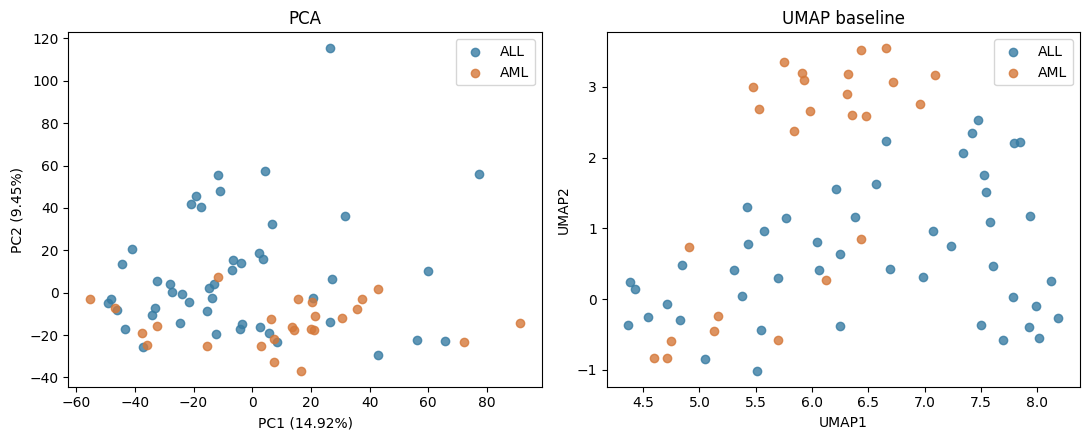

PCA/UMAP 对照图： d:\桌面\zy-workplace3\git-practice-classroom\.tmp\dimension-reduction\student-results\pca_umap_comparison.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

baseline = embeddings["baseline_n15_min01_seed42"]

for label, color in [
    ("ALL", "#387ca3"),
    ("AML", "#d57839")
]:
    mask = df["diagnosis"].eq(label).to_numpy()

    axes[0].scatter(
        scores[mask, 0],
        scores[mask, 1],
        label=label,
        color=color,
        alpha=0.8
    )

    axes[1].scatter(
        baseline[mask, 0],
        baseline[mask, 1],
        label=label,
        color=color,
        alpha=0.8
    )

axes[0].set(
    xlabel=f"PC1 ({evr[0]:.2%})",
    ylabel=f"PC2 ({evr[1]:.2%})",
    title="PCA"
)

axes[1].set(
    xlabel="UMAP1",
    ylabel="UMAP2",
    title="UMAP baseline"
)

for ax in axes:
    ax.legend()

fig.tight_layout()

comparison_path = results_dir / "pca_umap_comparison.png"
fig.savefig(comparison_path, dpi=160, bbox_inches="tight")

plt.show()
print("PCA/UMAP 对照图：", comparison_path)

### 3.4 用最近五个邻居辅助判断稳定性

In [12]:
from sklearn.neighbors import NearestNeighbors

def find_five_neighbors(embedding):
    """
    返回每个样本在二维 UMAP 图中的最近五个邻居。
    查询 6 个点是因为第一个通常是样本自己，需要去掉。
    """
    model = NearestNeighbors(
        n_neighbors=6,
        metric="euclidean"
    ).fit(embedding)

    indices = model.kneighbors(
        embedding,
        return_distance=False
    )

    return [set(row[1:]) for row in indices]


baseline_neighbors = find_five_neighbors(
    embeddings["baseline_n15_min01_seed42"]
)

comparison_names = [
    "neighbors5_min01_seed42",
    "neighbors15_min05_seed42",
    "neighbors15_min01_seed7",
]

neighbor_stability = pd.DataFrame({
    "sample_id": df["sample_id"]
})

for name in comparison_names:
    changed_neighbors = find_five_neighbors(
        embeddings[name]
    )

    overlap = [
        len(base & changed) / 5
        for base, changed in zip(
            baseline_neighbors,
            changed_neighbors
        )
    ]

    neighbor_stability[name] = overlap

    print(
        f"基线与 {name} 的平均五邻居重合率："
        f"{np.mean(overlap):.1%}"
    )

stability_path = (
    results_dir
    / "umap_neighbor_stability.csv"
)

neighbor_stability.to_csv(
    stability_path,
    index=False
)

print("\n逐样本邻居重合率：", stability_path)
print(neighbor_stability.head().to_string(index=False))

基线与 neighbors5_min01_seed42 的平均五邻居重合率：55.3%
基线与 neighbors15_min05_seed42 的平均五邻居重合率：64.2%
基线与 neighbors15_min01_seed7 的平均五邻居重合率：60.3%

逐样本邻居重合率： d:\桌面\zy-workplace3\git-practice-classroom\.tmp\dimension-reduction\student-results\umap_neighbor_stability.csv
sample_id  neighbors5_min01_seed42  neighbors15_min05_seed42  neighbors15_min01_seed7
     G001                      0.8                       1.0                      0.8
     G002                      0.4                       1.0                      0.8
     G003                      0.6                       0.8                      0.8
     G004                      1.0                       1.0                      1.0
     G005                      0.8                       0.8                      0.6


In [13]:
# 列出各 UMAP 设置中每个样本的最近五个邻居编号
def ranked_five_neighbor_indices(embedding):
    model = NearestNeighbors(n_neighbors=5, metric="euclidean").fit(embedding)
    # 不传入查询矩阵时，scikit-learn 会自动排除样本自身
    return model.kneighbors(return_distance=False)

ranked_neighbors = {
    name: ranked_five_neighbor_indices(embedding)
    for name, embedding in embeddings.items()
}
layout_names = list(embeddings.keys())
baseline_name = layout_names[0]
neighbor_rows = []

for row_index, sample_id in enumerate(df["sample_id"]):
    neighbors_by_layout = {
        name: ranked_neighbors[name][row_index].tolist()
        for name in layout_names
    }
    common_indices = set(neighbors_by_layout[baseline_name])
    for name in layout_names[1:]:
        common_indices &= set(neighbors_by_layout[name])

    neighbor_rows.append({
        "sample_id": sample_id,
        "baseline_neighbors": ", ".join(df["sample_id"].iloc[neighbors_by_layout[baseline_name]]),
        "neighbors5_neighbors": ", ".join(df["sample_id"].iloc[neighbors_by_layout[layout_names[1]]]),
        "min_dist05_neighbors": ", ".join(df["sample_id"].iloc[neighbors_by_layout[layout_names[2]]]),
        "seed7_neighbors": ", ".join(df["sample_id"].iloc[neighbors_by_layout[layout_names[3]]]),
        "common_neighbors_all_four": ", ".join(df["sample_id"].iloc[sorted(common_indices)]),
        "common_count_all_four": len(common_indices),
    })

stable_neighbor_ids = pd.DataFrame(neighbor_rows)
stable_ids_path = results_dir / "umap_neighbor_ids.csv"
stable_neighbor_ids.to_csv(stable_ids_path, index=False)
print("各样本在四种设置下的最近邻编号，按共同邻居数量排序：")
display(
    stable_neighbor_ids
    .sort_values(["common_count_all_four", "sample_id"], ascending=[False, True])
    .head(15)
)
print("完整邻居编号表：", stable_ids_path)

各样本在四种设置下的最近邻编号，按共同邻居数量排序：


,sample_id,baseline_neighbors,neighbors5_neighbors,min_dist05_neighbors,seed7_neighbors,common_neighbors_all_four,common_count_all_four
3,G004,"G008, G001, G027, G007, G049","G008, G007, G001, G049, G027","G008, G001, G049, G007, G027","G049, G027, G008, G001, G007","G001, G007, G008, G027, G049",5
7,G008,"G007, G004, G027, G049, G001","G004, G007, G001, G049, G027","G007, G049, G004, G027, G001","G007, G004, G027, G001, G049","G001, G004, G007, G027, G049",5
19,G020,"G069, G068, G048, G015, G013","G048, G013, G015, G068, G069","G069, G068, G048, G015, G013","G048, G068, G069, G015, G013","G013, G015, G048, G068, G069",5
0,G001,"G003, G004, G027, G049, G008","G004, G008, G003, G007, G049","G003, G004, G049, G027, G008","G004, G003, G008, G049, G017","G003, G004, G008, G049",4
6,G007,"G008, G027, G004, G049, G035","G008, G004, G049, G027, G001","G008, G049, G027, G004, G032","G008, G004, G027, G049, G053","G004, G008, G027, G049",4
29,G030,"G036, G050, G031, G051, G053","G051, G050, G036, G031, G034","G036, G050, G031, G051, G028","G036, G050, G031, G063, G051","G031, G036, G050, G051",4
32,G033,"G032, G053, G028, G040, G038","G028, G037, G032, G038, G053","G032, G038, G028, G053, G007","G053, G038, G028, G032, G036","G028, G032, G038, G053",4
47,G048,"G013, G069, G020, G015, G068","G020, G068, G013, G015, G069","G005, G068, G015, G069, G020","G020, G015, G068, G013, G069","G015, G020, G068, G069",4
48,G049,"G027, G008, G007, G004, G001","G027, G007, G008, G004, G001","G027, G008, G007, G001, G004","G027, G004, G007, G008, G003","G004, G007, G008, G027",4
49,G050,"G030, G036, G051, G031, G037","G036, G030, G051, G053, G037","G051, G030, G036, G037, G028","G051, G036, G037, G030, G031","G030, G036, G037, G051",4


完整邻居编号表： d:\桌面\zy-workplace3\git-practice-classroom\.tmp\dimension-reduction\student-results\umap_neighbor_ids.csv


### 3.5 UMAP 实际结果与解释

四组 UMAP 均使用同一个标准化矩阵 `Z`，输入形状为 `(72, 7129)`；诊断标签没有参与拟合，只在绘图时用于着色。UMAP 版本为 `0.5.12`。坐标表形状为 `(72, 12)`，已保存到 `.tmp/dimension-reduction/student-results/umap_coordinates.csv`。

基线图中，ALL 和 AML 在 UMAP2 方向上呈现一定分布差异，但仍有混合样本。将 `n_neighbors` 从 15 改为 5 后，局部布局和部分小团块发生了更明显的变化；将 `min_dist` 从 0.1 改为 0.5 后，点的聚集紧密程度改变，整体局部邻域相对更接近基线；改变随机种子后，图的方向和坐标范围明显改变，但样本之间仍保留一部分相近关系。

以基线的五个最近邻为参照，平均邻居重合率为：

| 对照 | 与基线的平均五邻居重合率 |
|---|---:|
| `n_neighbors=5` | 55.3% |
| `min_dist=0.5` | 64.2% |
| `random_state=7` | 60.3% |

这些结果表示局部关系有一定稳定性，但并没有完全稳定。在本次对照中，改变 `n_neighbors` 对邻域关系的影响最大，改变 `min_dist` 的平均影响较小。邻居重合率只是对当前数据和当前二维布局的辅助描述。

新增编号对照显示：G004 在四组设置下的五个最近邻都相同，为 G001、G007、G008、G027、G049；G008 的五个共同近邻为 G001、G004、G007、G027、G049；G020 的五个共同近邻为 G013、G015、G048、G068、G069。另有 7 份样本在四组设置中保留了 4/5 个共同近邻。这些例子说明有些局部关系较稳定，但不能据此推断疾病亚型或机制。完整逐样本结果保存在 `.tmp/dimension-reduction/student-results/umap_neighbor_ids.csv`。

| 比较项 | PCA | UMAP |
|---|---|---|
| 线性/非线性 | 线性投影 | 非线性嵌入 |
| 主要保留的信息 | 方差最大的正交方向 | 高维空间中的局部邻域关系 |
| 坐标轴含义 | 可通过探针权重解释 | UMAP1、UMAP2 没有固定生物学含义 |
| 方差解释率 | 可以报告，例如前两轴累计 24.3678% | 没有 PCA 意义上的方差解释率 |
| 距离解读 | 只是投影后的关系，未显示方向仍可能有差异 | 主要解读局部邻近，不直接解读岛屿间距离、面积或方向 |
| 参数与随机性 | 本次 PCA 设置较少，方向符号可整体翻转 | `n_neighbors`、`min_dist`、距离度量和随机种子都会影响布局 |
| 用于预测时避免泄露 | 在训练折内拟合并转换验证折 | 若用于预测，也必须只在训练折拟合 UMAP，再转换验证数据 |

UMAP 常用于单细胞或复杂表型展示，是因为这些数据可能存在非线性和多尺度的局部结构，二维 UMAP 可以帮助研究者提出候选邻域或分组假设。本次图形可以支持：在指定标准化方式和参数下，这批样本存在某些局部相似性和候选结构；不能证明疾病机制、真实亚型数量或新患者预测性能。由于数据中没有批次字段，也不能宣称已经排除批次影响。

图能支持什么／不能支持什么：

1. **图能支持的判断：**在同一标准化矩阵和指定参数下，部分样本之间存在可重复的局部邻近关系。例如 G004、G008、G020 在四组设置下都保留了相同的五个最近邻；与基线相比，三个对照的平均五邻居重合率为 `55.3%`、`64.2%` 和 `60.3%`。因此，本图可以作为“这批样本存在候选局部结构”的探索性证据。
2. **图不能支持的生物学判断：**不能把 UMAP 岛屿的数量当作真实亚型数量，也不能把岛屿之间的距离、方向、面积或紧密程度直接当作生物学差异大小。四组布局中这些外观会随 `n_neighbors`、`min_dist` 和随机种子改变，说明它们不是本数据中已经确定的生物学量。
3. **图不能支持的机制与预测判断：**不能仅凭 ALL/AML 在图上的分离证明疾病机制、因果关系或新患者预测能力。预测能力必须把标准化、降维和分类器放在训练折内拟合，再用未参与建模的验证集或外部队列评估；机制还需要独立的分子证据、功能实验或其他生物医学验证。
4. **批次结论的边界：**本数据没有批次字段，所以不能宣称已经排除批次影响。需要补充实验日期、芯片、平台等元数据，检查图中结构是否与批次一致，并在必要时使用预先说明的方法处理批次效应。

### 3.6 任务三问题逐项回答

回答：哪些邻近关系在不同设置下较稳定？岛屿数量、岛屿间距离、方向和面积是否稳定？为什么 UMAP 常用于单细胞或复杂表型展示？图上分离能否证明疾病机制、真实亚型数量或新患者预测性能？本数据缺少批次字段，能否宣称已经排除批次影响？

答：

1. **较稳定的邻近关系：**在四组二维 UMAP 布局中，G004、G008、G020 各自的五个最近邻始终相同，这表示这些样本的近邻集合在本次设置变化下较稳定，但邻居的远近排序仍可能改变。另有 7 份样本保留了 4/5 个共同近邻。三个对照与基线的平均五邻居重合率分别为 `55.3%`、`64.2%`、`60.3%`，说明部分局部关系保留，但整体并不完全稳定；这里衡量的是二维布局之间的一致性，不是高维邻域保真度或诊断准确率。

2. **岛屿数量、距离、方向和面积不稳定：**四组图中局部团块的形状、紧密程度、位置和方向会随参数或随机种子改变，因此这些外观不能当作稳定的生物学量。视觉上数出的岛屿数量也可能受布局与划分标准影响，本次没有进行独立聚类验证，不能将其认定为真实亚型数量；岛屿间距离、方向和面积也不能直接解释为生物学差异大小、疾病变化方向或某类样本的真实变异程度。

3. **UMAP常用于单细胞或复杂表型展示的原因：**这类数据通常包含很多测量指标，样本之间的相似关系可能不是简单的直线关系。UMAP 尝试把高维数据中的局部邻近关系展示在二维图上，让研究者更容易发现相似样本的聚集和候选分组，进而提出值得进一步验证的假设；二维图仍会丢失或扭曲部分关系。

4. **图上分离的结论边界：**分离只能提示在当前输入、预处理和参数下存在某些样本结构，不能单独证明疾病机制、真实亚型数量或对新患者的预测性能。机制需要独立生物学证据或功能实验，亚型需要独立数据与其他证据验证，预测性能需要在训练折内拟合全部处理步骤并进行验证，再用独立测试集或外部队列评估。

5. **批次影响：**不能宣称已经排除。批次是指不同实验日期、芯片或测量条件等可能带来的系统性差异；当前数据没有批次字段，无法检查这些差异是否解释了图中的结构。标准化和 UMAP 本身也不能证明批次影响已被消除，需补充实验元数据后再评估。


## 4. 证据边界结论

### 四句话结论：主张—证据—推理—边界

- **主张：**本次 PCA 和 UMAP 提示这 72 份白血病样本存在候选结构和部分较稳定的局部邻近关系，但仅凭二维图分离不足以证明发现了疾病机制或具备新患者预测能力。
- **证据：**标准化 PCA 的 PC1、PC2 分别解释 `14.9216%`、`9.4462%` 的输入总方差，前两轴累计 `24.3678%`；UMAP 分别只将 `n_neighbors` 改为 5、`min_dist` 改为 0.5、`random_state` 改为 7 时，与基线的平均五邻居重合率依次为 `55.3%`、`64.2%`、`60.3%`。
- **推理：**PCA 优先保留样本变化最大的方向而不直接优化 ALL/AML 区分，二维图只显示部分方差，UMAP 的局部布局又会受参数和随机性影响，因此图中模式只能帮助提出假设，解释率与邻居重合率都不能当作分类准确率或因果证据。
- **边界：**本次全部 72 份样本均参与描述性拟合，数据没有批次字段，且尚未训练和验证分类器，所以不能宣称排除了批次影响或量化了预测性能；预测主张需要在开发数据内完成方案选择并冻结后用独立外部队列评估，机制主张还需独立生物学证据或功能实验。

### 若要把图上的模式升级为生物医学结论，提出的一项额外验证方案：用独立外部队列检验预测主张

本方案是后续验证建议，尚未执行；它回应初始判断中“方法在没有参与分析的新样本上是否仍然有效”的疑问。

1. **准备独立数据：**收集没有参与本次探索、参数选择或模型训练的 ALL/AML 外部样本，尽量使用可比较的测量流程，并记录实验日期、平台等批次信息；本次全部 72 份样本已参与描述性分析，原始 34 个测试样本不能再当作完全未被查看的新外部队列。
2. **在开发数据内确定方案：**先明确分类方法，再把标准化、PCA 和分类器放入同一个 `Pipeline`；每一折只在训练折内拟合全部步骤，验证折只接受已有规则的转换和预测，根据开发数据内的验证结果确定主成分数量等设置。
3. **冻结方案后评估外部队列：**按固定方案在全部开发数据上重新拟合，把训练得到的标准化参数、PCA 方向和分类规则用于外部样本，不在外部样本上重新拟合这些步骤，也不根据外部测试结果反复调参。
4. **报告证据及限制：**报告混淆矩阵、ALL 与 AML 各自的召回率，以及 balanced accuracy（两类召回率的平均值），同时报告样本量和置信区间，说明表现估计的不确定性；外部表现较好只能支持该固定流程在相应人群中的预测能力，不能证明疾病机制或保证适用于所有新患者。

这些评价量的通俗含义：混淆矩阵是一张“真实类别与预测类别”的计数表；某一类的召回率，是这一类真实样本中被正确识别的比例；两类召回率取平均，就是这里的 balanced accuracy；置信区间用于表达有限样本带来的估计不确定性，不等于对每位新患者的正确率保证。

如果要检验“某个探针对应的基因或通路导致疾病”的机制主张，还需先核实探针与基因的对应关系，再结合独立分子证据或带适当对照的功能干预实验检验具体假设；不能只因 PC1 权重较大就把探针对应的基因称为致病基因，外部预测成功也不能替代机制验证。


### 三道作业题与回答

**作业：**用自己的话分别解释：

1. PCA 第一主成分代表什么？结合本次解释率和一个探针权重说明。

答：PCA 第一主成分（PC1）是全部探针经过加权后形成的第一条新坐标轴，它让 72 个样本投影后的方差最大。本次标准化 PCA 中 PC1 解释 `14.9216%` 的总方差；例如 `X92518_s_at` 的 PC1 权重为 `+0.028786`，表示该探针的标准化值越大，通常会对样本的 PC1 得分产生正向贡献，但它只是全部 7,129 个探针中的一个，不能单独代表 PC1 或证明致病作用。

2. 为什么 PCA 前通常需要考虑标准化？结合原尺度对照说明它的作用与代价。

答：因为 PCA 对方差较大的特征更敏感。如果不同探针的量纲或波动范围差别很大，未标准化时大尺度探针可能支配主成分；标准化让每个探针先以自己的均值和标准差换算到可比较的尺度。本次原尺度 PCA 的 PC1、PC2 解释率为 `17.4278%`、`10.3386%`，标准化后为 `14.9216%`、`9.4462%`，且两种方法的高权重探针不同，说明尺度会改变结果。代价是标准化可能放大低变异噪声，因此不能只看解释率高低决定哪种处理更好。

3. UMAP 图能说明什么，不能说明什么？结合一次参数或种子对照说明。

答：UMAP 可以在二维图中帮助观察高维数据的局部邻近关系和候选分组，不能直接说明机制、真实亚型数量或新患者预测性能。例如把 `n_neighbors` 从 15 改为 5 后，与基线的平均五邻居重合率为 `55.3%`；这说明部分局部关系保留，但布局并不完全稳定。UMAP1、UMAP2 没有固定的生物学含义，图上的方向、面积和岛屿间距离也不能直接作生物学解释。


## 5. 运行记录与 AI 使用说明

### 运行记录

- Python 版本：3.12.10
- 主要软件包版本：pandas 2.3.3、NumPy 2.3.5、scikit-learn 1.8.0、umap-learn 0.5.12
- 随机性与求解方式：UMAP 基线种子 42，种子对照 7；两次 PCA 均使用 svd_solver="full"，未使用随机求解器
- 输入特征：`leukemia.csv` 中排除 `sample_id`、`original_split`、`diagnosis` 后的 7,129 个探针；72 个样本，ALL 47、AML 25
- 标准化方式：`StandardScaler` 按探针列拟合，使用总体标准差 `ddof=0`；原尺度 PCA 仅中心化作为对照；含负值矩阵未直接取 `log`/`log1p`
- PCA/UMAP 的拟合范围：本次描述性分析在全部 72 个样本上拟合标准化、PCA 和四组 UMAP；诊断标签只在拟合后用于着色；不用于新样本预测性能评估
- 是否修改代码或参数；如修改，请说明：按作业要求新增 PC1 加权得分核对、原尺度 PCA、UMAP 参数/种子对照、五邻居稳定性和样本编号追踪；固定随机种子并使用 n_jobs=1 便于复现；不据此保证跨软件环境的坐标完全一致
- 可选交叉验证：未运行；尚无分类器训练或预测性能评估，外部队列和机制验证均为建议方案

### AI 使用说明

- 是否使用 AI：是
- AI 帮助了哪些环节：帮助解释 PCA、解释率、loading、UMAP、信息泄露和结果边界，并协助检查代码结构和补充 Markdown 说明。
- 我如何核查 AI 提供的解释或代码：在本地 notebook 中逐单元运行，核对实际输出、数据形状、软件版本、参数、保存的坐标表和邻居重合率；关键 PC1 得分用全部探针加权求和与 `pca.transform` 交叉核对。
